# Supervised comparison and error analysis

Classical candidates use grouped training CV with preprocessing fitted within each fold. The ANN used validation for early stopping and selection, so its tuning is different and it has no reported CV score. Select by validation MAE; the previously used midterm holdout is not an independent endterm test.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
while not (root / 'pyproject.toml').exists():
    if root == root.parent: raise RuntimeError('Run within the project')
    root = root.parent
r = root / 'reports/results/endterm'
f = root / 'reports/figures/endterm'

In [2]:
display(pd.read_csv(r/'supervised_tuning.csv').sort_values(['model','cv_mae']).groupby('model').head(3))
display(pd.read_csv(r/'model_comparison_validation.csv'))

,model,parameters,cv_mae,cv_std,cv_train_mae
0,Baseline (mean),{},4.635465,0.066801,4.634880
13,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",1.089671,0.016369,0.674257
12,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",1.090478,0.023657,0.538376
9,Decision Tree,"{""model__max_depth"": 16, ""model__min_samples_l...",1.090761,0.024186,0.688527
19,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",1.111760,0.032896,0.780732
24,KNN,"{""model__n_neighbors"": 4, ""model__p"": 1, ""mode...",1.116460,0.032136,0.547353
20,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",1.117026,0.032997,0.558646
1,Linear Regression,{},1.985638,0.036415,1.975658
4,Ridge,"{""model__alpha"": 1.0}",1.985554,0.036748,1.975883
3,Ridge,"{""model__alpha"": 0.1}",1.985567,0.036435,1.975694


,model,selected_parameters,train_mae,validation_mae,validation_rmse,validation_r2
0,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",0.685603,1.051024,1.636483,9.302561e-01
1,Feedforward ANN,"{""hidden_sizes"": [64, 32], ""learning_rate"": 0....",0.946014,1.082715,1.522971,9.395959e-01
2,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",0.778864,1.089423,1.672234,9.271755e-01
3,Linear Regression,{},1.976651,2.018650,2.777868,7.990415e-01
4,Ridge,"{""model__alpha"": 1.0}",1.976975,2.020508,2.778423,7.989612e-01
5,Baseline (mean),{},4.634994,4.661760,6.196671,-1.294925e-07


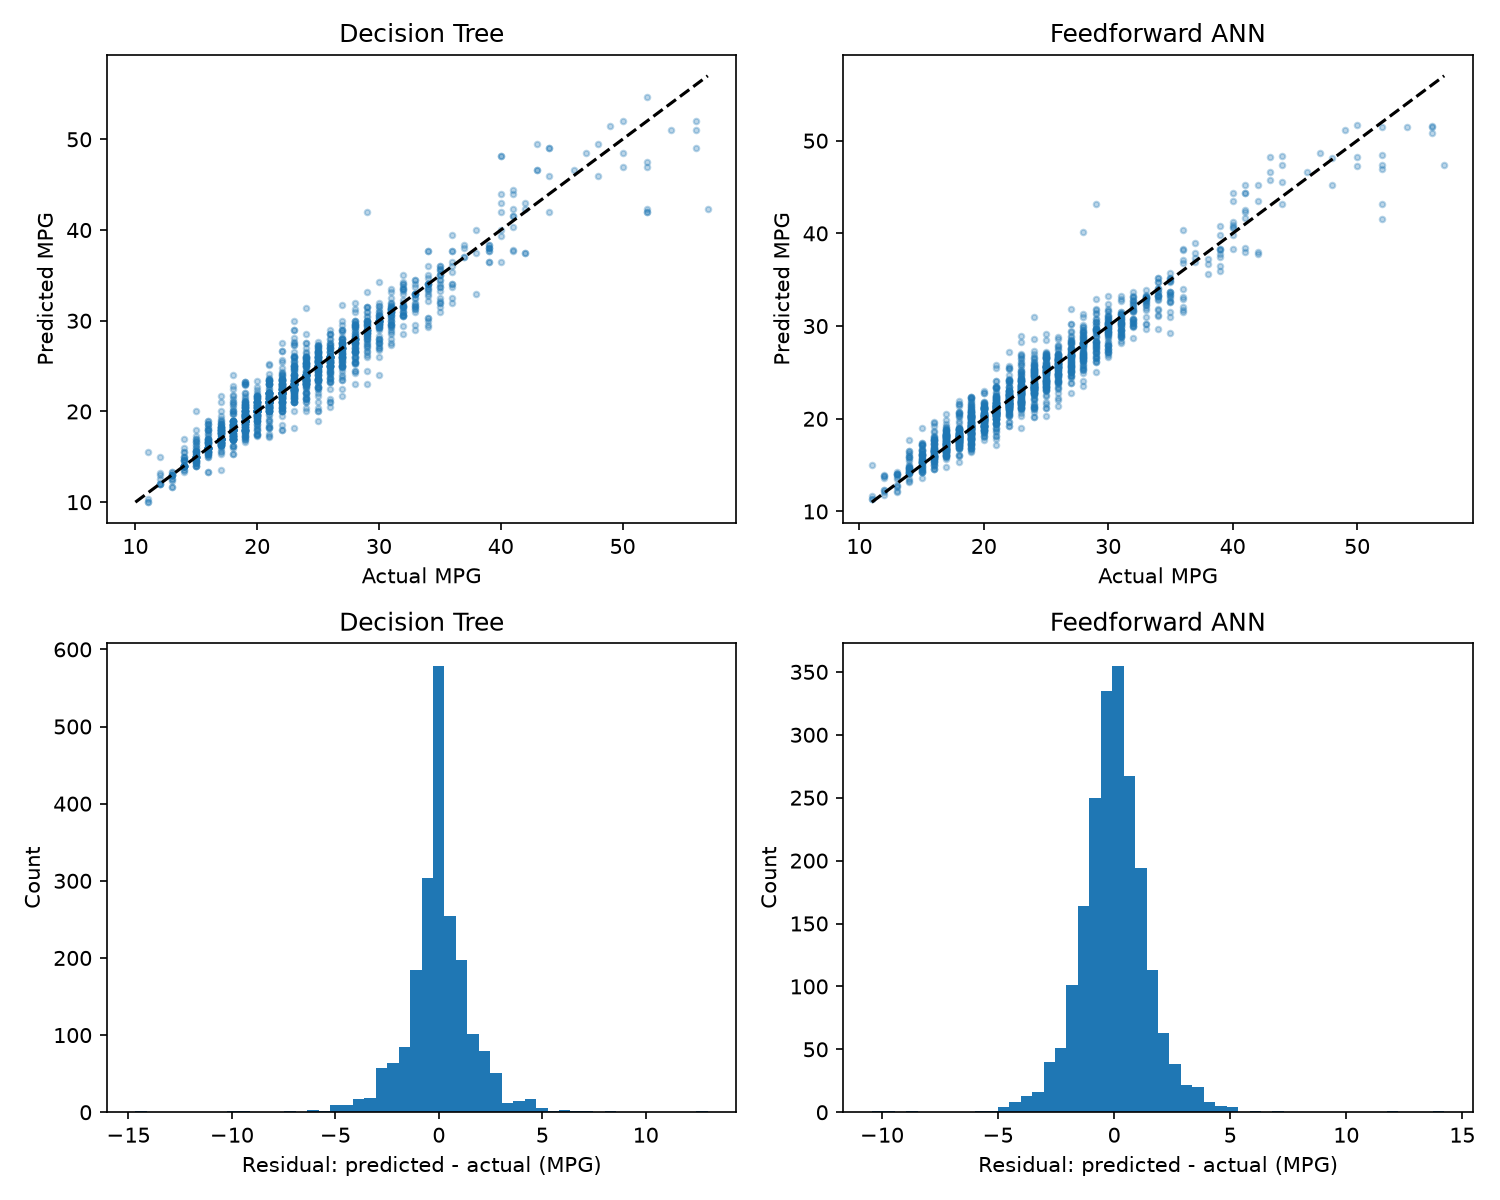

,model,group_type,group,n,mae,mean_error
0,Decision Tree,hybrid,0,1839,0.949319,-0.006826
1,Decision Tree,hybrid,1,241,1.827104,0.068302
2,Decision Tree,vehicle_class,Compact Cars,228,1.351831,0.049165
3,Decision Tree,vehicle_class,Large Cars,137,0.898297,0.021168
4,Decision Tree,vehicle_class,Midsize Cars,277,1.363534,0.013888
5,Decision Tree,vehicle_class,Midsize Station Wagons,18,1.670370,0.818519
6,Decision Tree,vehicle_class,Minicompact Cars,96,0.468320,0.020569
7,Decision Tree,vehicle_class,Minivan - 2WD,7,0.404762,0.261905
8,Decision Tree,vehicle_class,Minivan - 4WD,4,1.000000,-1.000000
9,Decision Tree,vehicle_class,Small Pickup Trucks 2WD,16,0.875000,-0.093750


,model_predictor,row_id,y_true,y_pred,make,model_vehicle,model_year,vehicle_class,hybrid,cylinders,displacement,error,absolute_error
0,Decision Tree,39963,57,42.333333,Toyota,Prius,2023,Midsize Cars,1,4.0,2.0,-14.666667,14.666667
1,Decision Tree,33230,29,42.000000,Buick,LaCrosse eAssist,2019,Midsize Cars,1,4.0,2.5,13.000000,13.000000
2,Decision Tree,31786,52,42.000000,Toyota,Camry Hybrid LE,2018,Midsize Cars,1,4.0,2.5,-10.000000,10.000000
3,Decision Tree,33765,52,42.000000,Toyota,Camry Hybrid LE,2019,Midsize Cars,1,4.0,2.5,-10.000000,10.000000
4,Decision Tree,39967,52,42.333333,Toyota,Prius XLE/LTD,2023,Midsize Cars,1,4.0,2.0,-9.666667,9.666667
5,Decision Tree,43268,40,48.200000,Honda,CR-V FWD,2026,Midsize Station Wagons,1,4.0,2.0,8.200000,8.200000
6,Decision Tree,44821,40,48.200000,Honda,CR-V FWD,2027,Midsize Station Wagons,1,4.0,2.0,8.200000,8.200000
7,Decision Tree,34956,24,31.400000,Ford,Fusion FWD,2020,Midsize Cars,0,4.0,2.5,7.400000,7.400000
8,Decision Tree,32693,56,49.000000,Toyota,Prius Eco,2018,Midsize Cars,1,4.0,1.8,-7.000000,7.000000
9,Decision Tree,42289,23,30.000000,Toyota,Tacoma Hybrid 4WD,2024,Standard Pickup Trucks 4WD,1,4.0,2.4,7.000000,7.000000


In [3]:
display(Image(filename=str(f/'evaluation_validation.png')))
display(pd.read_csv(r/'error_by_group_validation.csv'))
display(pd.read_csv(r/'largest_errors_validation.csv'))

Residuals are predicted minus actual MPG. Group MAE should be interpreted alongside group size; large residuals suggest hypotheses rather than proving causes. Related make/model variants can appear in different partitions, potentially making results optimistic for genuinely unseen models.

In [4]:
test = r/'model_comparison_test.csv'
if test.exists(): display(pd.read_csv(test))
else: print('Final evaluation on the previously used holdout has not been run.')

,model,mae,rmse,r2
0,Baseline (mean),4.586690,6.218473,-0.000332
1,Linear Regression,1.998093,2.782038,0.799782
2,Ridge,1.997433,2.781551,0.799852
3,Decision Tree,1.073831,1.663872,0.928383
4,KNN,1.070707,1.633091,0.931008
5,Feedforward ANN,1.078018,1.473056,0.943867
